# Modelagem e avaliação

## Leitura da base limpa e feature engineering

In [39]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Permite importar o src/ a partir da pasta notebooks/
raiz = Path.cwd().parent
sys.path.append(str(raiz))
from src.features import adicionar_comprometimento_renda

# Base limpa da etapa anterior (nulos ainda presentes, tratados no pipeline)
df = pd.read_csv(raiz / "data" / "credit_risk_limpo.csv")

# Mesma função que a API vai usar
df = adicionar_comprometimento_renda(df)

# Conferência: a nova feature é praticamente a loan_percent_income × 100
print(
    "Correlação com loan_percent_income:",
    round(df["comprometimento_renda"].corr(df["loan_percent_income"]), 4),
)
df[
    ["loan_amnt", "person_income", "comprometimento_renda", "loan_percent_income"]
].head()

Correlação com loan_percent_income: 0.9989


,loan_amnt,person_income,comprometimento_renda,loan_percent_income
0,1000,9600,10.416667,0.10
1,5500,9600,57.291667,0.57
2,35000,65500,53.435115,0.53
3,35000,54400,64.338235,0.55
4,2500,9900,25.252525,0.25


## Separando as colunas categóricas e numéricas

In [40]:
# y = alvo | X = variáveis explicativas
# loan_percent_income sai por ser redundante com comprometimento_renda
y = df["loan_status"]
X = df.drop(columns=["loan_status", "loan_percent_income"])

colunas_numericas = X.select_dtypes(include="number").columns.tolist()
colunas_categoricas = X.select_dtypes(exclude="number").columns.tolist()

print("Numéricas:", colunas_numericas)
print("Categóricas:", colunas_categoricas)

Numéricas: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'cb_person_cred_hist_length', 'comprometimento_renda']
Categóricas: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


## Split estratificado (antes de qualquer transformação)

In [41]:
from sklearn.model_selection import train_test_split

# 80% treino / 20% teste, mantendo a mesma proporção de inadimplentes nos dois
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Treino: {len(X_train)} | Teste: {len(X_test)}")
print(
    f"% inadimplentes no treino: {y_train.mean():.1%} | no teste: {y_test.mean():.1%}"
)

Treino: 25927 | Teste: 6482
% inadimplentes no treino: 21.9% | no teste: 21.9%


**Observação:** separei treino e teste antes de qualquer cálculo (imputação, escala ou encoding), para o modelo nunca "ver" dados do teste. O `stratify` manteve 21,9% de inadimplentes nos dois conjuntos.

## Pré-processamento encapsulado

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def criar_preprocessador(escalonar: bool) -> ColumnTransformer:
    """Imputa nulos com a mediana, escala as numéricas (se pedido) e codifica as categóricas."""
    passos_numericos = [("imputador", SimpleImputer(strategy="median"))]
    if escalonar:
        passos_numericos.append(("escalonador", StandardScaler()))

    return ColumnTransformer(
        [
            ("numericas", Pipeline(passos_numericos), colunas_numericas),
            (
                "categoricas",
                OneHotEncoder(handle_unknown="ignore"),
                colunas_categoricas,
            ),
        ]
    )

## Função de avaliação

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score


def avaliar(modelo, X, y, threshold=0.5):
    """Calcula F1, Recall e ROC-AUC de um modelo já treinado."""
    prob = modelo.predict_proba(X)[:, 1]  # probabilidade de ser inadimplente
    pred = (prob >= threshold).astype(int)  # classe final pelo ponto de corte
    return {
        "f1": f1_score(y, pred),
        "recall": recall_score(y, pred),
        "roc_auc": roc_auc_score(y, prob),
    }

## Treino das duas famílias

In [44]:
resultados = []
modelos = {}  # guarda os modelos treinados para a fase de avaliação

# Família 1: Regressão Logística (com escalonamento)
for C in [0.001, 0.01, 0.1, 1, 10]:
    modelo = Pipeline(
        [
            ("preprocessamento", criar_preprocessador(escalonar=True)),
            (
                "classificador",
                LogisticRegression(C=C, class_weight="balanced", max_iter=1000),
            ),
        ]
    )
    modelo.fit(X_train, y_train)  # fit SÓ no treino
    nome = f"LogReg C={C}"
    modelos[nome] = modelo
    treino, teste = avaliar(modelo, X_train, y_train), avaliar(modelo, X_test, y_test)
    resultados.append(
        {
            "familia": "Regressão Logística",
            "modelo": nome,
            **{f"{k}_treino": v for k, v in treino.items()},
            **{f"{k}_teste": v for k, v in teste.items()},
        }
    )

# Família 2: Random Forest (sem escalonamento)
for profundidade in [4, 8, 12, 16, None]:
    modelo = Pipeline(
        [
            ("preprocessamento", criar_preprocessador(escalonar=False)),
            (
                "classificador",
                RandomForestClassifier(
                    n_estimators=200,
                    max_depth=profundidade,
                    class_weight="balanced",
                    random_state=42,
                    n_jobs=-1,
                ),
            ),
        ]
    )
    modelo.fit(X_train, y_train)
    nome = f"RF depth={profundidade}"
    modelos[nome] = modelo
    treino, teste = avaliar(modelo, X_train, y_train), avaliar(modelo, X_test, y_test)
    resultados.append(
        {
            "familia": "Random Forest",
            "modelo": nome,
            **{f"{k}_treino": v for k, v in treino.items()},
            **{f"{k}_teste": v for k, v in teste.items()},
        }
    )

tabela = pd.DataFrame(resultados)
tabela["gap_f1"] = tabela["f1_treino"] - tabela["f1_teste"]  # diferença treino x teste
tabela.round(3)

,familia,modelo,f1_treino,recall_treino,roc_auc_treino,f1_teste,recall_teste,roc_auc_teste,gap_f1
0,Regressão Logística,LogReg C=0.001,0.617,0.775,0.859,0.628,0.783,0.863,-0.011
1,Regressão Logística,LogReg C=0.01,0.641,0.778,0.871,0.639,0.786,0.873,0.002
2,Regressão Logística,LogReg C=0.1,0.646,0.778,0.873,0.638,0.782,0.874,0.008
3,Regressão Logística,LogReg C=1,0.647,0.777,0.873,0.641,0.783,0.874,0.006
4,Regressão Logística,LogReg C=10,0.646,0.777,0.873,0.640,0.782,0.874,0.006
5,Random Forest,RF depth=4,0.702,0.757,0.894,0.706,0.769,0.895,-0.004
6,Random Forest,RF depth=8,0.779,0.778,0.931,0.770,0.779,0.922,0.009
7,Random Forest,RF depth=12,0.872,0.817,0.971,0.801,0.760,0.934,0.071
8,Random Forest,RF depth=16,0.956,0.923,0.998,0.818,0.757,0.937,0.139
9,Random Forest,RF depth=None,0.999,1.000,1.000,0.823,0.760,0.936,0.176


## Gráfico Treino × Teste

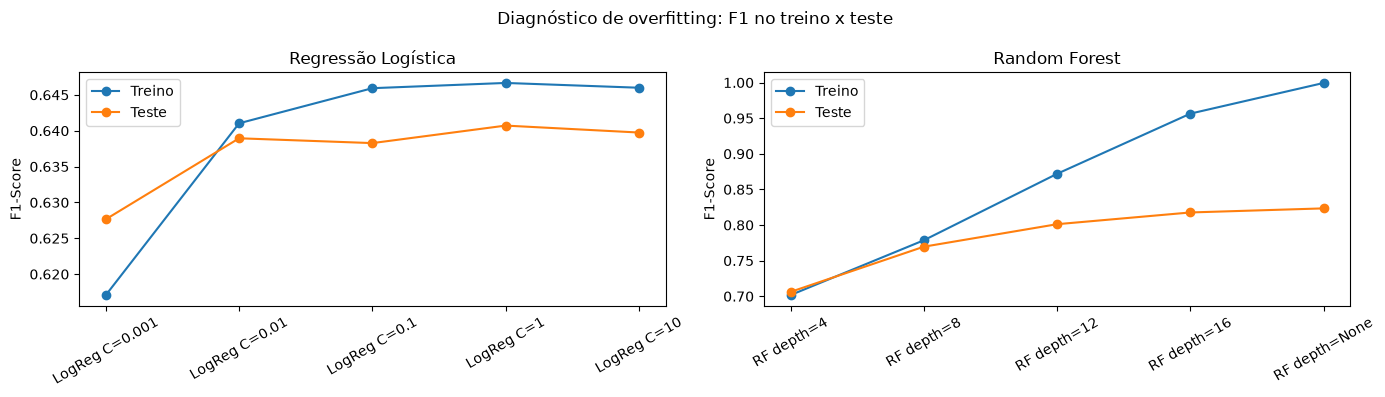

In [45]:
# F1 no treino x teste para cada família: onde as linhas se afastam, começa o overfitting
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))

for eixo, familia in zip(eixos, ["Regressão Logística", "Random Forest"]):
    dados = tabela[tabela["familia"] == familia]
    eixo.plot(dados["modelo"], dados["f1_treino"], marker="o", label="Treino")
    eixo.plot(dados["modelo"], dados["f1_teste"], marker="o", label="Teste")
    eixo.set_title(familia)
    eixo.set_ylabel("F1-Score")
    eixo.tick_params(axis="x", rotation=30)
    eixo.legend()

plt.suptitle("Diagnóstico de overfitting: F1 no treino x teste")
plt.tight_layout()
plt.show()

**Diagnóstico de overfitting:**
- **Regressão Logística:** treino e teste ficaram colados em todas as configurações, então não houve overfitting. A partir de `C=0.01` as métricas param de melhorar (F1 ~0,64 e ROC-AUC ~0,87). É o limite de um modelo linear nesta base.
- **Random Forest:** com profundidade 4 e 8, treino e teste andam juntos. Com 12, o treino começa a se afastar (diferença de 0,07). Com 16 e sem limite, o treino chega a F1 0,999: o modelo decorou os dados, e o teste quase não melhora.

Random Forest com profundidade 12 é o melhor equilíbrio: melhora o teste em relação à de 8 sem disparar o overfitting. Os dois finalistas são `LogReg C=1` e `RF depth=12`.

## Avaliação dos dois finalistas

===== LogReg C=1 =====
              precision    recall  f1-score   support

  Adimplente       0.93      0.81      0.87      5064
Inadimplente       0.54      0.78      0.64      1418

    accuracy                           0.81      6482
   macro avg       0.74      0.80      0.75      6482
weighted avg       0.85      0.81      0.82      6482

===== RF depth=12 =====
              precision    recall  f1-score   support

  Adimplente       0.93      0.96      0.95      5064
Inadimplente       0.85      0.76      0.80      1418

    accuracy                           0.92      6482
   macro avg       0.89      0.86      0.87      6482
weighted avg       0.92      0.92      0.92      6482



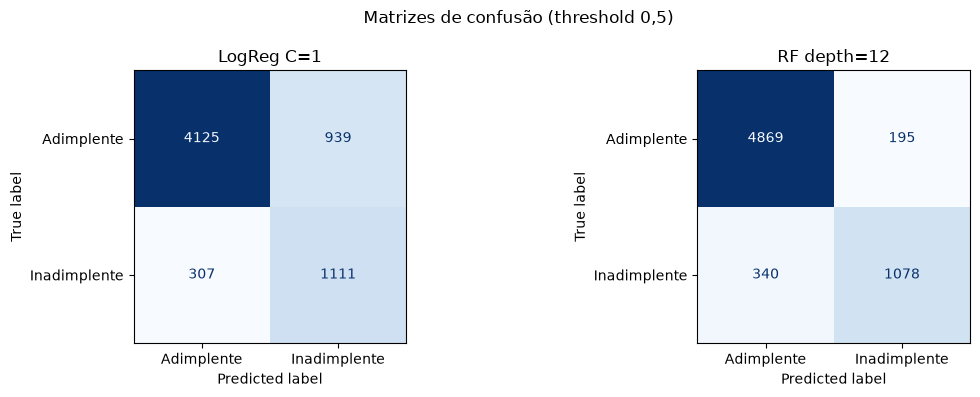

In [46]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

finalistas = ["LogReg C=1", "RF depth=12"]

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for eixo, nome in zip(eixos, finalistas):
    pred = modelos[nome].predict(X_test)  # ponto de corte padrão: 0,5
    print(f"===== {nome} =====")
    print(
        classification_report(y_test, pred, target_names=["Adimplente", "Inadimplente"])
    )
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        display_labels=["Adimplente", "Inadimplente"],
        cmap="Blues",
        ax=eixo,
        colorbar=False,
    )
    eixo.set_title(nome)

plt.suptitle("Matrizes de confusão (threshold 0,5)")
plt.tight_layout()
plt.show()

**Observação (threshold 0,5):** a Regressão Logística deixou passar 307 inadimplentes e recusou 939 bons pagadores. A Random Forest deixou passar 340 inadimplentes, mas recusou só 195 bons pagadores. Quando a RF diz que o cliente vai dar calote, ela acerta 85% das vezes, contra 54% da Regressão Logística.

## Custo financeiro e ajuste do threshold

**Premissas:** Falso Negativo (aprovar quem dá calote) custa o valor emprestado. Falso Positivo (recusar bom pagador) custa os juros de 1 ano que o banco deixa de ganhar.

In [47]:
import numpy as np

# Mediana dos juros calculada só no treino (para preencher nulos no cálculo do custo)
mediana_juros = X_train["loan_int_rate"].median()


def custo_total(X, y, prob, threshold):
    """Soma o prejuízo dos erros em dinheiro para um ponto de corte."""
    pred = (prob >= threshold).astype(int)
    juros = X["loan_int_rate"].fillna(mediana_juros) / 100

    falso_negativo = (y == 1) & (pred == 0)  # aprovou quem deu calote
    falso_positivo = (y == 0) & (pred == 1)  # recusou bom pagador

    perda_calote = X.loc[falso_negativo, "loan_amnt"].sum()
    perda_juros = (X.loc[falso_positivo, "loan_amnt"] * juros[falso_positivo]).sum()
    return perda_calote + perda_juros

## Melhor threshold (escolhido só no treino)

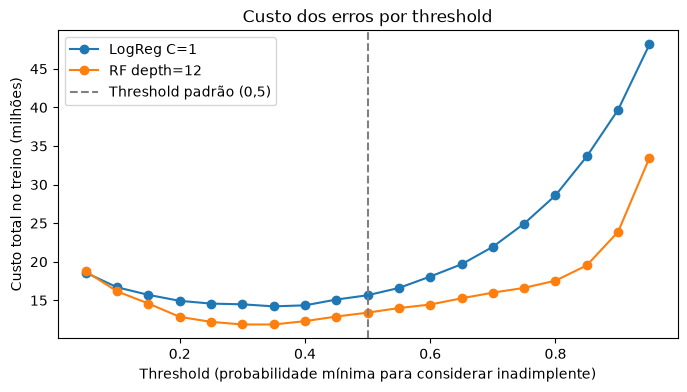

Melhor threshold: {'LogReg C=1': 0.35, 'RF depth=12': 0.3}


In [48]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict

limiares = np.arange(0.05, 0.96, 0.05)
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
melhor_threshold = {}

plt.figure(figsize=(8, 4))
for nome in finalistas:
    # Probabilidades "fora da amostra" dentro do treino (o teste não é usado aqui)
    prob_treino = cross_val_predict(
        clone(modelos[nome]), X_train, y_train, cv=validacao, method="predict_proba"
    )[:, 1]
    custos = [custo_total(X_train, y_train, prob_treino, t) for t in limiares]
    melhor_threshold[nome] = round(float(limiares[np.argmin(custos)]), 2)
    plt.plot(limiares, np.array(custos) / 1e6, marker="o", label=nome)

plt.axvline(0.5, color="gray", linestyle="--", label="Threshold padrão (0,5)")
plt.xlabel("Threshold (probabilidade mínima para considerar inadimplente)")
plt.ylabel("Custo total no treino (milhões)")
plt.title("Custo dos erros por threshold")
plt.legend()
plt.show()

print("Melhor threshold:", melhor_threshold)

**Observação:**
- As duas curvas têm formato de "U". Com o threshold muito baixo, o modelo recusa quase todo mundo e o banco perde os juros de muitos bons pagadores. Com o threshold alto, ele aprova quase todo mundo e o custo dos calotes dispara (passa de 45 milhões na Regressão Logística).
- O ponto mais baixo de cada curva é o melhor threshold: **0,30 para a Random Forest** e **0,35 para a Regressão Logística**. Nos dois casos fica abaixo do padrão de 0,5 (linha cinza), porque deixar passar um calote custa bem mais do que recusar um bom pagador.
- A curva da Random Forest fica abaixo da Regressão Logística em praticamente todos os pontos: ela erra menos em dinheiro, qualquer que seja o threshold.

## Resultado no teste (0,5 × threshold ajustado)

In [49]:
from sklearn.metrics import precision_score

linhas = []
for nome in finalistas:
    prob_teste = modelos[nome].predict_proba(X_test)[:, 1]
    for t in [0.5, melhor_threshold[nome]]:
        pred = (prob_teste >= t).astype(int)
        linhas.append(
            {
                "modelo": nome,
                "threshold": t,
                "calotes_aprovados (FN)": int(((y_test == 1) & (pred == 0)).sum()),
                "bons_recusados (FP)": int(((y_test == 0) & (pred == 1)).sum()),
                "recall": round(recall_score(y_test, pred), 3),
                "precisao": round(precision_score(y_test, pred), 3),
                "custo_total": round(custo_total(X_test, y_test, prob_teste, t)),
            }
        )

comparacao = pd.DataFrame(linhas)
comparacao

,modelo,threshold,calotes_aprovados (FN),bons_recusados (FP),recall,precisao,custo_total
0,LogReg C=1,0.50,307,939,0.783,0.542,4074418
1,LogReg C=1,0.35,200,1570,0.859,0.437,3513208
2,RF depth=12,0.50,340,195,0.760,0.847,3416320
3,RF depth=12,0.30,177,1048,0.875,0.542,2890801


## Matriz de confusão do campeão com o threshold ajustado

              precision    recall  f1-score   support

  Adimplente       0.96      0.79      0.87      5064
Inadimplente       0.54      0.88      0.67      1418

    accuracy                           0.81      6482
   macro avg       0.75      0.83      0.77      6482
weighted avg       0.87      0.81      0.82      6482



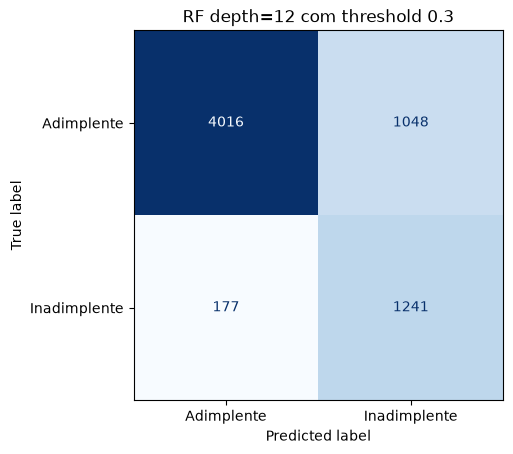

In [50]:
# Matriz do campeão com o threshold escolhido pelo custo
campeao = "RF depth=12"
threshold_campeao = melhor_threshold[campeao]

prob_teste = modelos[campeao].predict_proba(X_test)[:, 1]
pred_campeao = (prob_teste >= threshold_campeao).astype(int)

print(
    classification_report(
        y_test, pred_campeao, target_names=["Adimplente", "Inadimplente"]
    )
)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_campeao,
    display_labels=["Adimplente", "Inadimplente"],
    cmap="Blues",
    colorbar=False,
)
plt.title(f"{campeao} com threshold {threshold_campeao}")
plt.show()

**Observação:** com threshold 0,30, o modelo identificou 1.241 dos 1.418 inadimplentes (87,5%) e só 177 calotes foram aprovados. Em troca, recusou 1.048 bons pagadores, um custo aceitável porque cada calote vale muito mais que os juros perdidos.

## Veredito

**Qual erro custa mais caro:** aprovar um cliente que vai dar calote (Falso Negativo). O banco perde o valor emprestado inteiro, enquanto recusar um bom pagador (Falso Positivo) só faz perder os juros. Por isso, vale a pena baixar o threshold e recusar mais clientes duvidosos.

**Modelo campeão: Random Forest (profundidade 12) com threshold 0,30.**
- Teve o menor custo no teste: R$ 2,89 milhões, contra R$ 3,51 milhões da melhor Regressão Logística.
- Em relação ao threshold padrão de 0,5, o custo caiu de R$ 3,42 para R$ 2,89 milhões (uma economia de cerca de R$ 526 mil), e os calotes aprovados caíram de 340 para 177.
- O preço disso é recusar mais bons pagadores (de 195 para 1.048), mas como cada calote custa muito mais que os juros perdidos, a conta fecha a favor.
- O threshold foi escolhido só com o treino (validação cruzada), então o resultado no teste é uma avaliação honesta.

## Salvando o pipeline campeão

In [51]:
import joblib

# Artefato: pipeline completo (pré-processamento + modelo) + threshold + colunas esperadas
artefato = {
    "modelo": modelos[campeao],
    "threshold": threshold_campeao,
    "colunas": X.columns.tolist(),
    "nome": campeao,
}

caminho_modelo = raiz / "models" / "modelo_risco_credito.joblib"
joblib.dump(
    artefato, caminho_modelo, compress=3
)  # compress reduz o arquivo de ~20 MB para ~5 MB
print("Modelo salvo em:", caminho_modelo)

# Conferência: carrega de volta e testa em 3 clientes do teste
carregado = joblib.load(caminho_modelo)
print("Threshold salvo:", carregado["threshold"])
print(
    "Probabilidades:", carregado["modelo"].predict_proba(X_test.head(3))[:, 1].round(3)
)

Modelo salvo em: c:\Users\luizhomem\Desktop\Projeto_Final_M3\M3_Projeto_Final_Risco_Credito\models\modelo_risco_credito.joblib
Threshold salvo: 0.3
Probabilidades: [0.332 0.349 0.187]
